# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

- **Устройство:** Kaggle, GPU Tesla T4; бонус 6.4 замерялся на CPU x86_64
- **Модель:** [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), ревизия `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT
- **Датасет:** Collection3, [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3) (ветка `refs/convert/parquet`)
- **Модель для сравнения (6.2):** [`DeepPavlov/rubert-base-cased`](https://huggingface.co/DeepPavlov/rubert-base-cased), ревизия `4036cab694767a299f2b9e6492909664d9414229`, в карточке лицензия не указана
- **Бонусы:** 6.2, 6.3, 6.4, 6.5
- **Нерешённые задачи:** нет

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}  # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
from huggingface_hub import HfApi
print(HfApi().model_info('cointegrated/rubert-tiny2').sha)

e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae


In [6]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я выбрала `cointegrated/rubert-tiny2` с лицензией MIT. Это компактный BERT, обученный специально для русского языка, а мой датасет как раз состоит из русских новостей. Модель маленькая, около 29M параметров, 3 слоя и hidden 312, поэтому на T4 она дообучается за минуты и я могу спокойно делать несколько запусков.

Для сравнения, `DeepPavlov/rubert-base-cased` весит около 180M и имеет 12 слоёв. На NER она обычно даёт на несколько пунктов F1 больше, но учится в разы дольше. Многоязычная `xlm-roberta-base` ещё тяжелее (около 280M), и большая часть её словаря приходится на другие языки. Поэтому я жду от tiny2 качество чуть ниже, чем у базовых моделей, зато быструю работу.

Если не зафиксировать `revision`, через полгода владелец может перезалить веса, токенизатор или конфиг. Тогда у меня изменятся сабворды и метрики, могут упасть загрузка или тесты, а если репозиторий удалят, ноутбук вообще перестанет запускаться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}

    def count(module):
        # сумма чисел во всех тензорах-параметрах модуля
        return sum(p.numel() for p in module.parameters())

    base = model.base_model          # сам энкодер без головы (у BERT это model.bert)

    # 1. эмбеддинги
    n_emb = count(base.embeddings)

    # 2. слои энкодера: каждый слой отдельно, encoder = их сумма
    layers = []
    for layer in base.encoder.layer:
        layers.append(count(layer))
    n_enc = sum(layers)

    # 3. голова token classification: Linear(H, K)
    n_head = count(model.classifier)

    # 4. всё остальное (у BERT будет 0)
    total = count(model)
    n_other = total - n_emb - n_enc - n_head

    return {'embeddings': n_emb, 'encoder': n_enc, 'head': n_head,
            'other': n_other, 'layers': layers}

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]

# 1. токенизация: слова уже разбиты, поэтому is_split_into_words=True;
#    padding=True дополняет короткое предложение до длины длинного
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')

# 2. прямой проход без градиентов, просим вернуть выходы всех слоёв
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

# 3. формы
print('input_ids      ', tuple(enc['input_ids'].shape))
print('attention_mask ', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    name = 'embeddings' if i == 0 else f'layer {i}'
    print(f'hidden_states[{i}] ({name}):', tuple(h.shape))
print('logits         ', tuple(out.logits.shape))

# 4. как слова разрезались на сабворды
for i in range(len(demo_texts)):
    print(enc.tokens(i))
    print(enc.word_ids(i))

input_ids       (2, 11)
attention_mask  (2, 11)
hidden_states[0] (embeddings): (2, 11, 312)
hidden_states[1] (layer 1): (2, 11, 312)
hidden_states[2] (layer 2): (2, 11, 312)
hidden_states[3] (layer 3): (2, 11, 312)
logits          (2, 11, 7)
['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
[None, 0, 1, 1, 2, 3, 4, 4, 4, 5, None]
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']
[None, 0, 0, 0, 1, 2, 3, 4, 5, None, None]


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 10.6 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** На вход подаётся батч из двух предложений, после токенизации `input_ids` и `attention_mask` имеют форму `(2, 11)`, то есть 2 предложения по 11 сабвордов. Блок эмбеддингов превращает каждый сабворд в вектор размера 312, получается `hidden_states[0]` формы `(2, 11, 312)`. Затем идут 3 одинаковых слоя энкодера, каждый из которых сохраняет форму `(2, 11, 312)` (`hidden_states[1]`, `[2]`, `[3]`). Голова `Linear(312, 7)` применяется к каждому токену и выдаёт logits формы `(2, 11, 7)`. Прямой проход батча 32 × 64 занимает у меня 10.6 мс на Tesla T4.

Больше всего параметров в эмбеддингах, 26.8M из 29.1M (92.1%). Почти все они приходятся на таблицу словаря размером 83828 × 312, а три слоя энкодера вместе занимают всего 2.3M (по 767 184 на слой), голова и того меньше (2 191). У маленькой модели с большим словарём основная часть параметров уходит на хранение векторов слов, а не на вычисления.

Токены обмениваются информацией только внутри слоёв энкодера, в механизме attention. Эмбеддинги, FFN внутри слоя и голова классификации обрабатывают каждый токен независимо.

`T` в logits больше числа слов по трём причинам. Токенизатор режет редкие слова на сабворды, например «Чайковский» превращается в `Чайк` и `##овский`, а «Воткинске» в `Вот`, `##кинс` и `##ке`. Особенно заметно это на английском предложении, где незнакомая для русской модели аббревиатура ITMO распалась на три сабворда `IT`, `##M` и `##O`. В начало и конец добавляются спецтокены `[CLS]` и `[SEP]`. Второе предложение короче первого, поэтому его дополнили токеном `[PAD]` до общей длины 11. Из-за этого в первом предложении 6 слов, а во втором 6 слов, но у обоих по 11 позиций.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None

raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')

if 'validation' not in raw:
    parts = raw['train'].train_test_split(test_size=0.1, seed=SEED)
    raw = DatasetDict(train=parts['train'], validation=parts['test'], test=raw['test'])

tag_feature = raw['train'].features['ner_tags'].feature
if hasattr(tag_feature, 'names'):
    LABEL_NAMES = list(tag_feature.names)
else:
    LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

print(raw)
print(raw['train'].features)
print('LABEL_NAMES:', LABEL_NAMES)
ex = raw['train'][0]
print(list(zip(ex['tokens'], [LABEL_NAMES[i] for i in ex['ner_tags']])))

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
{'id': Value('string'), 'tokens': List(Value('string')), 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']))}
LABEL_NAMES: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Дополнение', 'O'), (':', 'O'), ('Д', 'B-PER'), ('.', 'I-PER'), ('Медведев', 'I-PER'), ('присвоил', 'O'), ('звания', 'O'), ('сотрудников', 'O'), ('полиции', 'O'), ('и', 'O'), ('переназначил', 'O'), ('14', 'O'), ('руководителей', 'O'), ('УВД', 'B-ORG'), (',', 'O'), ('ГУВД', 'B-ORG'), ('и', 'O'), ('МВД', 'B-ORG'), ('по', 'O'), ('субъектам', 'O'), ('РФ', 'B-LOC'), ('.', 'O')]


split        sentences     LOC     ORG     PER   total
train             9301    4881    5960    7406   18247
validation        2153    1168    1308    1641    4117
test              1922    1175    1256    1570    4001

длина спана в словах -> число спанов: {1: 13086, 2: 8774, 3: 3061, 4: 540, 5: 280, 6: 345, 7: 95, 8: 88, 9: 32, 10: 30, 11: 13, 12: 5, 13: 7, 14: 2, 15: 3, 16: 3, 18: 1}
LOC: средняя длина 1.31, максимум 8
ORG: средняя длина 1.98, максимум 18
PER: средняя длина 2.02, максимум 10
train: слов в предложении среднее 20.2, медиана 18, 95% 41, максимум 256
validation: слов в предложении среднее 20.4, медиана 18, 95% 41, максимум 118
test: слов в предложении среднее 20.9, медиана 19, 95% 42, максимум 122
train в сабвордах: медиана 22, 99% 69, максимум 331, длиннее MAX_LENGTH=128: 10


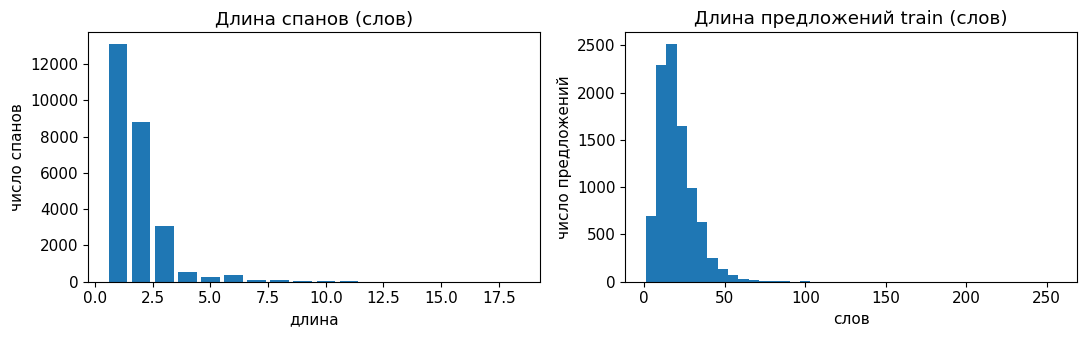

In [15]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
def count_spans(tag_names):
    result = []
    cur_type, cur_len = None, 0
    for tag in tag_names:
        if tag != 'O' and tag.startswith('I-') and tag[2:] == cur_type:
            cur_len += 1
            continue
        if cur_type is not None:
            result.append((cur_type, cur_len))
        if tag == 'O':
            cur_type, cur_len = None, 0
        else:
            cur_type, cur_len = tag[2:], 1
    if cur_type is not None:
        result.append((cur_type, cur_len))
    return result


split_names = ['train', 'validation', 'test']
type_counts = {}
span_lengths = collections.Counter()
span_len_by_type = collections.defaultdict(list)
sent_lengths = {}

for split in split_names:
    type_counts[split] = collections.Counter()
    sent_lengths[split] = []
    for ex in raw[split]:
        tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
        sent_lengths[split].append(len(ex['tokens']))
        for ent_type, length in count_spans(tags):
            type_counts[split][ent_type] += 1
            span_lengths[length] += 1
            span_len_by_type[ent_type].append(length)

# 1. таблица: число предложений и сущностей по типам и сплитам
types = sorted({t for c in type_counts.values() for t in c})
print(f'{"split":<12}{"sentences":>10}' + ''.join(f'{t:>8}' for t in types) + f'{"total":>8}')
for split in split_names:
    row = f'{split:<12}{len(raw[split]):>10}'
    for t in types:
        row += f'{type_counts[split][t]:>8}'
    row += f'{sum(type_counts[split].values()):>8}'
    print(row)

# 2. длины спанов
print('\nдлина спана в словах -> число спанов:', dict(sorted(span_lengths.items())))
for t in types:
    print(f'{t}: средняя длина {np.mean(span_len_by_type[t]):.2f}, максимум {max(span_len_by_type[t])}')

# 3. длины предложений в словах и в сабвордах
for split in split_names:
    lens = np.array(sent_lengths[split])
    print(f'{split}: слов в предложении среднее {lens.mean():.1f}, медиана {np.median(lens):.0f}, '
          f'95% {np.percentile(lens, 95):.0f}, максимум {lens.max()}')
sub_lens = [len(tokenizer(ws, is_split_into_words=True)['input_ids']) for ws in raw['train']['tokens']]
print(f'train в сабвордах: медиана {np.median(sub_lens):.0f}, 99% {np.percentile(sub_lens, 99):.0f}, '
      f'максимум {max(sub_lens)}, длиннее MAX_LENGTH={MAX_LENGTH}: {sum(l > MAX_LENGTH for l in sub_lens)}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
lengths = sorted(span_lengths)
axes[0].bar(lengths, [span_lengths[l] for l in lengths])
axes[0].set(title='Длина спанов (слов)', xlabel='длина', ylabel='число спанов')
axes[1].hist(sent_lengths['train'], bins=40)
axes[1].set(title='Длина предложений train (слов)', xlabel='слов', ylabel='число предложений')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Я взяла датасет Collection3. Это русские новостные тексты, собранные на основе коллекции Persons-1000 в НИВЦ МГУ. Сущности размечены вручную тремя типами, PER (персоны), ORG (организации) и LOC (локации), в схеме BIO. В датасете уже есть готовые сплиты: 9301 предложение в train, 2153 в validation и 1922 в test.

Типы распределены довольно ровно. Чаще всего встречаются персоны (около 40% сущностей), реже всего локации (около 27%), так что совсем редкого класса нет. Пропорции во всех сплитах почти одинаковые.

Больше всего коротких спанов. Из одного слова состоят 13086 спанов, из двух 8774, из трёх 3061, длиннее пяти слов совсем мало. Локации самые короткие (в среднем 1.31 слова), у персон и организаций около двух слов. При этом у организаций встречаются очень длинные названия, до 18 слов, и именно на них я ожидаю ошибки границ. В предложении в среднем 20 слов (медиана 18), и только 10 предложений train длиннее `MAX_LENGTH = 128` сабвордов, поэтому обрезка почти ничего не теряет.

На обучение может повлиять несколько особенностей. Инициалы с точкой разбиты на отдельные токены (`Д` `.` `Медведев`), и модель должна понять, что точка внутри имени. Некоторые решения разметчиков спорные, например «РФ» размечено как LOC, хотя по смыслу это может быть и организация. Ручная разметка обычно чистая, но такие пограничные случаи между ORG и LOC, скорее всего, дадут ошибки типа.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start = None
    cur_type = None

    for i, tag in enumerate(tags):
        if tag == 'O':
            if cur_type is not None:
                spans.append((start, i, cur_type))
                cur_type = None
            continue

        prefix = tag[0]
        ent_type = tag[2:]

        if prefix == 'I' and ent_type == cur_type:
            continue

        if cur_type is not None:
            spans.append((start, i, cur_type))
        start = i
        cur_type = ent_type

    if cur_type is not None:
        spans.append((start, len(tags), cur_type))
    return spans



def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, ent_type in spans:
        tags[start] = 'B-' + ent_type
        for j in range(start + 1, end):
            tags[j] = 'I-' + ent_type
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels = []
    prev_word = None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev_word:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            lab = word_labels[w]
            labels.append(b_to_i.get(lab, lab))
        prev_word = w
    return labels

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)

for split in ['train', 'validation', 'test']:
    path = Path('data') / f'{split}_spans.jsonl'

    # 1. BIO -> спаны -> JSONL
    with open(path, 'w', encoding='utf-8') as f:
        for ex in raw[split]:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            record = {'tokens': ex['tokens'], 'spans': [list(s) for s in bio_to_spans(tags)]}
            f.write(json.dumps(record, ensure_ascii=False) + '\n')

    # 2. читаем обратно -> BIO -> сравниваем с исходником
    n_same, n_diff, n_spans = 0, 0, 0
    diff_example = None
    with open(path, encoding='utf-8') as f:
        for line, ex in zip(f, raw[split]):
            record = json.loads(line)
            spans = [tuple(s) for s in record['spans']]
            back = spans_to_bio(spans, len(record['tokens']))
            orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
            n_spans += len(spans)
            assert record['tokens'] == list(ex['tokens'])
            assert bio_to_spans(back) == bio_to_spans(orig)
            if back == orig:
                n_same += 1
            else:
                n_diff += 1
                if diff_example is None:
                    diff_example = list(zip(ex['tokens'], orig, back))

    print(f'{split}: {path}, предложений {n_same + n_diff}, спанов {n_spans}, '
          f'совпало дословно {n_same}, отличается (невалидный BIO в исходнике) {n_diff}')
    if diff_example:
        print('  пример расхождения (слово, исходный тег, восстановленный):',
              [x for x in diff_example if x[1] != x[2]][:5])

train: data/train_spans.jsonl, предложений 9301, спанов 18247, совпало дословно 9296, отличается (невалидный BIO в исходнике) 5
  пример расхождения (слово, исходный тег, восстановленный): [('о', 'I-PER', 'B-PER')]
validation: data/validation_spans.jsonl, предложений 2153, спанов 4117, совпало дословно 2153, отличается (невалидный BIO в исходнике) 0
test: data/test_spans.jsonl, предложений 1922, спанов 4001, совпало дословно 1921, отличается (невалидный BIO в исходнике) 1
  пример расхождения (слово, исходный тег, восстановленный): [('Первоуральск', 'I-ORG', 'B-ORG')]


In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Слово часто режется на несколько сабвордов, например «переназначил» превращается в `перена`, `##зна` и `##чил`. Если ставить метку на каждый кусок, длинные слова будут сильнее влиять на loss, а у продолжений появятся неестественные теги `B-`. Поэтому метку получает только первый сабворд, и по нему же потом предсказывается тег слова. Остальные сабворды и спецтокены `[CLS]`, `[SEP]`, `[PAD]` получают `-100`. Это `ignore_index` в cross-entropy, такие позиции не участвуют ни в loss, ни в градиенте.

По `MAX_LENGTH = 128` в train обрезано 10 предложений из 9301, а слов без сабвордов или за обрезкой 434, это около 0.2% всех слов train, и почти все они из хвостов этих длинных предложений. Таким словам `predict_word_tags` ставит `O`, поэтому сущность в обрезанном хвосте засчитается как пропуск и немного снизит recall. На итоговый F1 это почти не влияет.

Collection3 уже размечен по словам в BIO, поэтому я сделала обратную конвертацию. Я перевела BIO в спаны, сохранила их в `data/<split>_spans.jsonl`, прочитала файл обратно и снова собрала BIO. Спаны совпали во всех сплитах. Дословно теги не совпали в 5 предложениях train, 0 validation и 1 test. Во всех этих случаях в исходнике стоит `I-X` без `B-X`, например слово «Первоуральск» помечено `I-ORG` сразу после `O`, а одиночное «о» помечено `I-PER`. Это похоже на ошибки разметчиков. Моя функция трактует такой тег как начало нового спана, так же как `seqeval`, поэтому смысл разметки не меняется. Вложенных и пересекающихся спанов в BIO быть не может, а расхождений токенизации нет, потому что датасет уже разбит на слова и токенизатор получает их через `is_split_into_words=True`.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    # 1. для каждого слова считаем, сколько раз встречался каждый тег
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1

    # 2. оставляем для слова самый частый тег
    tagger = {}
    for word, tag_counter in counts.items():
        best_tag, best_count = tag_counter.most_common(1)[0]
        tagger[word] = best_tag
    return tagger


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    tags = []
    for word in words:
        tags.append(tagger.get(word, 'O'))
    return tags

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

# 1. словарный бейзлайн: учим на train, предсказываем validation
train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority_tagger, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)

# сколько слов validation модель вообще видела в train
n_words = sum(len(ws) for ws in val_tokens)
n_known = sum(w in majority_tagger for ws in val_tokens for w in ws)
print(f'словарь: {len(majority_tagger)} слов, знакомых слов в validation {n_known / n_words:.1%}')

# 2. предобученный энкодер со случайной головой, без дообучения
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
random_model = random_model.cpu()

pred_counter = collections.Counter(t for tags in random_pred for t in tags)
gold_counter = collections.Counter(t for tags in val_gold for t in tags)
print('теги случайной головы:', dict(pred_counter.most_common()))
print('истинные теги:        ', dict(gold_counter.most_common()))

print(f'\n{"бейзлайн":<14}{"F1 micro":>10}{"F1 macro":>10}{"precision":>11}{"recall":>9}')
for name, s in baseline.items():
    print(f'{name:<14}{s["f1_micro"]:>10.3f}{s["f1_macro"]:>10.3f}{s["precision"]:>11.3f}{s["recall"]:>9.3f}')

print('\nmajority по типам:')
print(classification_report(val_gold, majority_pred, digits=3, zero_division=0))

словарь: 27410 слов, знакомых слов в validation 88.8%


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

теги случайной головы: {'O': 11544, 'I-PER': 11459, 'B-PER': 8688, 'I-LOC': 4833, 'B-LOC': 3053, 'I-ORG': 2511, 'B-ORG': 1768}
истинные теги:         {'O': 36570, 'B-PER': 1641, 'I-PER': 1615, 'B-ORG': 1308, 'I-ORG': 1199, 'B-LOC': 1168, 'I-LOC': 355}

бейзлайн        F1 micro  F1 macro  precision   recall
majority           0.561     0.579      0.563    0.560
random_head        0.038     0.035      0.022    0.130

majority по типам:
              precision    recall  f1-score   support

         LOC      0.753     0.763     0.758      1168
         ORG      0.549     0.576     0.562      1308
         PER      0.428     0.403     0.415      1641

   micro avg      0.563     0.560     0.561      4117
   macro avg      0.577     0.581     0.579      4117
weighted avg      0.559     0.560     0.559      4117



**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн получил на validation F1 micro 0.561 и macro 0.579 (precision 0.563, recall 0.560). Лучше всего он справляется с локациями (F1 0.758), потому что города и страны в новостях повторяются постоянно. С организациями хуже (0.562), а с персонами совсем плохо (0.415). Имена людей в новостях всё время новые, и фамилии из validation часто не встречались в train. Кроме того, бейзлайн не смотрит на контекст. Одно и то же слово всегда получает один тег, поэтому он не отличает «Россию» как страну от «России» внутри названия партии, а в многословных спанах легко путает `B-` и `I-`. Recall ограничен ещё и тем, что знакомых слов в validation только 88.8%, а всё незнакомое сразу получает `O`.

Энкодер со случайной головой даёт F1 всего 0.038. Он почти не предсказывает `O`, из 43 856 слов он отдал `O` только 11 544, хотя на самом деле таких слов 36 570. Остальным словам достались случайные `I-PER`, `B-PER`, `I-LOC` и другие теги. Получилась масса ложных сущностей, поэтому precision всего 0.022, а recall 0.130 набирается случайными совпадениями. Энкодер действительно предобучен и выдаёт осмысленные векторы слов, но голова `Linear(312, 7)` инициализирована случайно и не знает, какому направлению в этом пространстве соответствует какой тег. Пока голову не обучили на наших метках, она проецирует хорошие признаки в случайные классы.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [23]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4
WARMUP_RATIO = 0.1 # первые 10% шагов lr плавно растёт от 0
WEIGHT_DECAY = 0.01


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer

    # 1. заморозка: учится только голова classifier, энкодер не меняется
    if freeze_encoder:
        for param in model.base_model.parameters():
            param.requires_grad = False
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'обучаемых параметров: {n_trainable:,}')

    # 2. сколько всего шагов, чтобы eval был примерно 10 раз за обучение
    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = steps_per_epoch * epochs
    eval_every = max(1, total_steps // 10)
    log_every = max(1, total_steps // 20)

    # 3. настройки обучения (названия аргументов как в transformers 5)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        warmup_steps=int(WARMUP_RATIO * total_steps),
        weight_decay=WEIGHT_DECAY,
        lr_scheduler_type='linear',
        eval_strategy='steps',
        eval_steps=eval_every,
        logging_strategy='steps',
        logging_steps=log_every,
        logging_first_step=True,
        save_strategy='no',
        fp16=torch.cuda.is_available(),   # на T4 смешанная точность ускоряет обучение
        report_to='none',
        seed=SEED,
    )

    # 4. Trainer; коллатор дополняет батч до одной длины, а labels - значением -100
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(tok),
        processing_class=tok,
    )

    # 5. обучение с замером времени
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    history = trainer.state.log_history
    return history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

обучаемых параметров: 29,098,303
{'loss': '1.83', 'grad_norm': '8.532', 'learning_rate': '0', 'epoch': '0.003436'}
{'loss': '1.117', 'grad_norm': '1.084', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}
{'loss': '0.2779', 'grad_norm': '1.354', 'learning_rate': '0.0001954', 'epoch': '0.2955'}
{'eval_loss': '0.1322', 'eval_runtime': '0.5145', 'eval_samples_per_second': '4185', 'eval_steps_per_second': '66.08', 'epoch': '0.299'}
{'loss': '0.1371', 'grad_norm': '2.02', 'learning_rate': '0.0001896', 'epoch': '0.4433'}
{'loss': '0.09985', 'grad_norm': '0.6861', 'learning_rate': '0.0001786', 'epoch': '0.5911'}
{'eval_loss': '0.07155', 'eval_runtime': '0.7429', 'eval_samples_per_second': '2898', 'eval_steps_per_second': '45.77', 'epoch': '0.5979'}
{'loss': '0.08308', 'grad_norm': '1.304', 'learning_rate': '0.0001677', 'epoch': '0.7388'}
{'loss': '0.07815', 'grad_norm': '2.197', 'learning_rate': '0.0001567', 'epoch': '0.8866'}
{'eval_loss': '0.05601', 'eval_runtime': '0.5129', 'eval_samples_pe

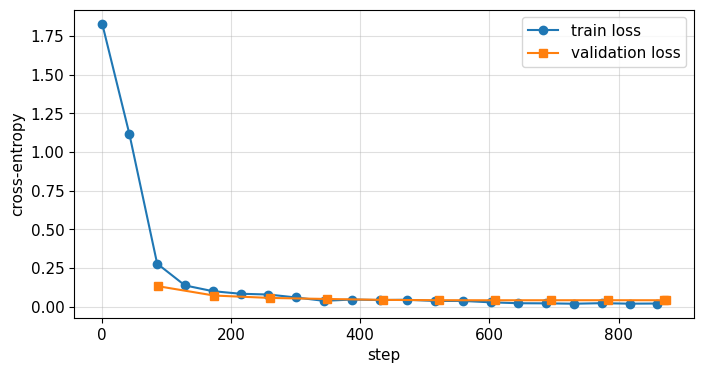

In [24]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Я взяла learning rate 2e-4, потому что у rubert-tiny2 всего 3 слоя и hidden 312, и маленькой модели нужен шаг больше, чем базовым моделям с их 2e-5 - 5e-5. Batch size 32 спокойно помещается в память T4 при длине до 128 сабвордов и даёт достаточно стабильный градиент. Первые 10% шагов идёт warmup, lr плавно растёт от нуля до 2e-4, а потом линейно падает к нулю. Так случайно инициализированная голова не ломает предобученный энкодер большими градиентами в начале, и на логе видно, что норма градиента сначала около 8.5, а потом держится в районе 1. Weight decay 0.01 даёт лёгкую регуляризацию, а `fp16` ускоряет обучение на T4. Три эпохи я выбрала как обычный бюджет для дообучения энкодера на датасете такого размера.

Стартовый loss 1.83 близок к ln 7 ≈ 1.95, то есть к уровню случайного угадывания среди 7 тегов. Дальше loss очень быстро падает, уже к концу первой трети эпохи validation loss равен 0.13. Минимум validation loss 0.041 модель достигает к началу третьей эпохи, после этого он стоит на месте (0.0410, 0.0411, 0.0413, 0.0411), а train loss продолжает снижаться до 0.02. Небольшой разрыв между кривыми говорит о начале переобучения, но качество на validation не падает. Больше эпох не нужно, примерно двух хватило бы с тем же результатом.

Обучение на полном train из 9301 предложения за 3 эпохи (873 шага) заняло 33.7 секунды на Tesla T4.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [25]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = 0        # слово предсказано не O и тег совпал с истинным
    n_pred = 0    # сколько слов модель пометила не O
    n_gold = 0    # сколько слов на самом деле не O

    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            if p != 'O':
                n_pred += 1
                if p == g:
                    tp += 1
            if g != 'O':
                n_gold += 1

    if n_pred == 0 and n_gold == 0:
        return 0.0
    precision = tp / n_pred if n_pred > 0 else 0.0
    recall = tp / n_gold if n_gold > 0 else 0.0
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)

In [26]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

# предсказания на validation и test
val_pred = predict_word_tags(model, val_tokens)

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)

print('=== validation ===')
print(classification_report(val_gold, val_pred, digits=3, zero_division=0))
print('=== test ===')
print(classification_report(test_gold, test_pred, digits=3, zero_division=0))

# итоговые метрики на test
final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final['per_type'] = {t: {'precision': report[t]['precision'], 'recall': report[t]['recall'],
                         'f1': report[t]['f1-score'], 'support': int(report[t]['support'])}
                     for t in ENTITY_TYPES}

# то же для validation
val_scores = entity_scores(val_gold, val_pred)
val_scores['token_f1'] = token_f1(val_gold, val_pred)
final['validation'] = val_scores

print(f'{"сплит":<12}{"F1 micro":>10}{"F1 macro":>10}{"precision":>11}{"recall":>9}{"token F1":>10}')
for name, s in [('validation', val_scores), ('test', final)]:
    print(f'{name:<12}{s["f1_micro"]:>10.3f}{s["f1_macro"]:>10.3f}{s["precision"]:>11.3f}'
          f'{s["recall"]:>9.3f}{s["token_f1"]:>10.3f}')
print(f'\nдля сравнения, словарный бейзлайн на validation: F1 micro {baseline["majority"]["f1_micro"]:.3f}')

=== validation ===
              precision    recall  f1-score   support

         LOC      0.949     0.942     0.945      1168
         ORG      0.839     0.894     0.866      1308
         PER      0.962     0.984     0.973      1641

   micro avg      0.918     0.943     0.931      4117
   macro avg      0.917     0.940     0.928      4117
weighted avg      0.919     0.943     0.931      4117

=== test ===
              precision    recall  f1-score   support

         LOC      0.952     0.952     0.952      1175
         ORG      0.849     0.880     0.864      1256
         PER      0.955     0.983     0.969      1570

   micro avg      0.920     0.942     0.931      4001
   macro avg      0.919     0.939     0.928      4001
weighted avg      0.921     0.942     0.931      4001

сплит         F1 micro  F1 macro  precision   recall  token F1
validation       0.931     0.928      0.918    0.943     0.955
test             0.931     0.928      0.920    0.942     0.955

для сравнения, с

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test модель получила F1 micro 0.931 и macro 0.928 (precision 0.920, recall 0.942), это на 0.37 выше словарного бейзлайна. Хуже всего распознаются организации, у ORG F1 0.864, а у LOC 0.952 и у PER 0.969. По частоте ORG не редкий тип, в train организаций даже больше, чем локаций. Дело в самих спанах. Названия организаций самые разнообразные и самые длинные, в среднем почти 2 слова и до 18 слов, часто с уточнениями вроде «Федеральная служба по тарифам», поэтому модели трудно попасть точно в обе границы. Кроме того, организации легко спутать с локациями, например «РФ» или «Кремль». Для персон всё наоборот по сравнению со словарным бейзлайном. Там PER был худшим (0.415), а у модели он почти лучший, потому что модель смотрит на контекст («сказал», «заявил», инициалы с точкой) и узнаёт даже незнакомые фамилии.

Micro F1 (0.931) чуть выше macro (0.928). Micro считает все сущности вместе, и в нём больше вес у частых персон, которые распознаются хорошо. Macro усредняет три типа поровну, поэтому слабый ORG тянет его вниз сильнее. Разница маленькая, потому что типы распределены довольно ровно.

Токенный F1 (0.955) выше F1 по сущностям (0.931). Токенный F1 даёт частичный кредит. Если в длинном названии организации модель верно пометила 3 слова из 4, она получает 3 верных слова, а по сущностям весь спан засчитывается как ошибка. Поэтому разница между метриками показывает в основном ошибки границ, и больше всего их как раз у длинных ORG. Пользователю NER нужен F1 по сущностям, ему важно получить целиком «Федеральную службу по тарифам», а не отдельные слова из неё.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [27]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']

def overlaps(a, b):
    # спаны (start, end, type), end не включается; пересекаются, если есть общее слово
    return a[0] < b[1] and b[0] < a[1]

def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    result = []

    # 1. каждый истинный спан получает ровно одну категорию
    for g in gold_spans:
        if g in pred_spans:
            result.append(('correct', g, g))
            continue

        same_type = None    # первый пересекающийся предсказанный спан того же типа
        other_type = None   # первый пересекающийся предсказанный спан другого типа
        for p in pred_spans:
            if overlaps(g, p):
                if p[2] == g[2] and same_type is None:
                    same_type = p
                if p[2] != g[2] and other_type is None:
                    other_type = p

        if same_type is not None:
            result.append(('boundary', g, same_type))
        elif other_type is not None:
            result.append(('type', g, other_type))
        else:
            result.append(('missed', g, None))

    # 2. предсказанный спан, не пересекающийся ни с одним истинным, это лишний спан
    for p in pred_spans:
        touches_gold = False
        for g in gold_spans:
            if overlaps(g, p):
                touches_gold = True
        if not touches_gold:
            result.append(('spurious', None, p))

    return result

In [28]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {c: 0 for c in ERROR_CATEGORIES}
examples = {c: [] for c in ERROR_CATEGORIES}

for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred)):
    for cat, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        errors[cat] += 1
        examples[cat].append((i, g, p))

# 1. числа и доли среди ошибок
n_errors = sum(errors[c] for c in ERROR_CATEGORIES if c != 'correct')
print(f'{"категория":<10}{"число":>7}{"доля среди ошибок":>20}')
for c in ERROR_CATEGORIES:
    share = '' if c == 'correct' else f'{errors[c] / n_errors:.1%}'
    print(f'{c:<10}{errors[c]:>7}{share:>20}')
print(f'всего ошибок {n_errors}')

# распределение ошибок по типам сущностей
by_type = collections.defaultdict(collections.Counter)
for c in ERROR_CATEGORIES:
    for _, g, p in examples[c]:
        by_type[c][(g or p)[2]] += 1
print('\nпо типам:', {c: dict(by_type[c]) for c in ERROR_CATEGORIES})

# 2. примеры: по 2 на каждую категорию ошибок
def span_text(words, span):
    if span is None:
        return '-'
    return f'[{" ".join(words[span[0]:span[1]])}] {span[2]}'

rng_ex = random.Random(SEED)
for c in ['boundary', 'type', 'missed', 'spurious']:
    print(f'\n=== {c} ===')
    for i, g, p in rng_ex.sample(examples[c], min(2, len(examples[c]))):
        words = val_tokens[i]
        print('предложение:', ' '.join(words))
        print('   истина:      ', span_text(words, g))
        print('   предсказание:', span_text(words, p))

категория   число   доля среди ошибок
correct      3884                    
boundary      158               45.5%
type           50               14.4%
missed         25                7.2%
spurious      114               32.9%
всего ошибок 347

по типам: {'correct': {'PER': 1614, 'LOC': 1100, 'ORG': 1170}, 'boundary': {'ORG': 114, 'PER': 20, 'LOC': 24}, 'type': {'ORG': 9, 'LOC': 36, 'PER': 5}, 'missed': {'ORG': 15, 'LOC': 8, 'PER': 2}, 'spurious': {'ORG': 84, 'LOC': 22, 'PER': 8}}

=== boundary ===
предложение: Кроме того , в рамках " правительственного часа " на вопросы депутатов ответит министр энергетики Александр Новак , а также глава Федеральной службы по тарифам Сергей Новиков .
   истина:       [Федеральной службы] ORG
   предсказание: [Федеральной службы по тарифам] ORG
предложение: Александр Галдин родился в 1948 году в селе Самарино Ряжского района Рязанской области .
   истина:       [Самарино] LOC
   предсказание: [Самарино Ряжского района] LOC

=== type ===
предложение: Г

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Самая частая категория ошибок связана с границами. Это 158 из 347 ошибок (45.5%), дальше идут лишние спаны (32.9%), ошибки типа (14.4%) и пропуски (7.2%). Верно найдены 3884 из 4117 истинных спанов. Почти все ошибки границ (114 из 158) и большинство лишних спанов (84 из 114) приходятся на организации.

В ошибках границы модель находит сущность, но захватывает больше слов, чем в разметке. Вместо «Самарино» она выделила «Самарино Ряжского района», а вместо «Федеральной службы» выделила «Федеральной службы по тарифам». Ошибки типа бывают у коротких аббревиатур и у слов, которые могут быть и местом, и именем. «Вашингтон» в значении американского правительства модель приняла за фамилию. Два пропуска из примеров («МВД» и «РФ») находятся в самом конце очень длинного предложения, которое длиннее 128 сабвордов. Этот хвост обрезан по `MAX_LENGTH`, и модель его просто не видела, это прямое следствие обрезки из 2.2. Лишние спаны модель ставит на реальные названия, которых нет в разметке, например газета «Коммерсант» или «КАД».

Заметная часть ошибок на самом деле относится к разметке. Полное название ведомства действительно «Федеральная служба по тарифам», и здесь модель права, а разметка обрывает спан. «МСФО» (международные стандарты финансовой отчётности) размечено как LOC, хотя это вообще не локация. «Коммерсант» это организация, а «КАД» название дороги, так что эти лишние спаны скорее пропуски разметчиков. Включать ли уточнения вроде «Ряжского района» в название, разметчики тоже решают непоследовательно.

Чтобы уменьшить ошибки границ, я бы добавила поверх энкодера слой CRF, который учитывает переходы между тегами, или взяла модель крупнее, например `rubert-base-cased`, которая лучше понимает длинный контекст (в 6.2 она подняла F1 по ORG заметнее всего). Пропуски в хвостах длинных предложений можно убрать, если увеличить `MAX_LENGTH` или резать такие предложения на перекрывающиеся окна. Но сначала я бы проверила, насколько ошибки границ вызваны непоследовательной разметкой, потому что такие ошибки модель исправить не может.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

обучаемых параметров: 2,191
{'loss': '1.83', 'grad_norm': '4.868', 'learning_rate': '0', 'epoch': '0.003436'}
{'loss': '1.783', 'grad_norm': '4.314', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}
{'loss': '1.395', 'grad_norm': '2.935', 'learning_rate': '0.0001954', 'epoch': '0.2955'}
{'eval_loss': '1.082', 'eval_runtime': '0.5636', 'eval_samples_per_second': '3820', 'eval_steps_per_second': '60.33', 'epoch': '0.299'}
{'loss': '0.9021', 'grad_norm': '1.216', 'learning_rate': '0.0001896', 'epoch': '0.4433'}
{'loss': '0.627', 'grad_norm': '0.8116', 'learning_rate': '0.0001786', 'epoch': '0.5911'}
{'eval_loss': '0.5248', 'eval_runtime': '0.5004', 'eval_samples_per_second': '4302', 'eval_steps_per_second': '67.94', 'epoch': '0.5979'}
{'loss': '0.5269', 'grad_norm': '0.6996', 'learning_rate': '0.0001677', 'epoch': '0.7388'}
{'loss': '0.4781', 'grad_norm': '0.4613', 'learning_rate': '0.0001567', 'epoch': '0.8866'}
{'eval_loss': '0.3987', 'eval_runtime': '0.7544', 'eval_samples_per_second':

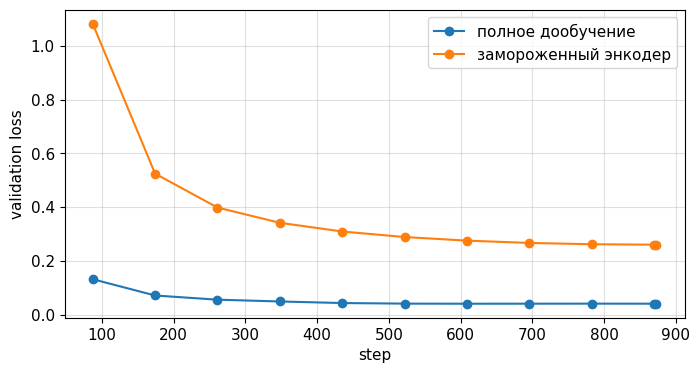

In [29]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'

# 1. та же модель и те же гиперпараметры, но учится только голова
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
RUN_TIMES['train_freeze_sec'] = frozen_seconds

# 2. метрики на validation, оценка по словам
frozen_pred = predict_word_tags(frozen_model, val_tokens)
frozen_scores = entity_scores(val_gold, frozen_pred)
frozen_scores['token_f1'] = token_f1(val_gold, frozen_pred)
frozen_model = frozen_model.cpu()

# 3. число обучаемых параметров в обоих вариантах
n_total = sum(p.numel() for p in model.parameters())
n_frozen_trainable = sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)

def last_eval_loss(hist):
    return [h['eval_loss'] for h in hist if 'eval_loss' in h][-1]

ablation = {
    'setting': ABLATION,
    'full': dict(val_scores, train_sec=train_seconds, trainable_params=n_total,
                 final_eval_loss=last_eval_loss(history)),
    'freeze': dict(frozen_scores, train_sec=frozen_seconds, trainable_params=n_frozen_trainable,
                   final_eval_loss=last_eval_loss(frozen_history)),
}


print(f'\n{"вариант":<8}{"F1 micro":>10}{"F1 macro":>10}{"token F1":>10}{"eval loss":>11}{"время, c":>10}{"обучаемых":>13}')
for name in ['full', 'freeze']:
    r = ablation[name]
    print(f'{name:<8}{r["f1_micro"]:>10.3f}{r["f1_macro"]:>10.3f}{r["token_f1"]:>10.3f}'
          f'{r["final_eval_loss"]:>11.3f}{r["train_sec"]:>10.1f}{r["trainable_params"]:>13,}')
print('\nfreeze по типам:')
print(classification_report(val_gold, frozen_pred, digits=3, zero_division=0))

plt.figure(figsize=(8, 4))
for name, hist in [('полное дообучение', history), ('замороженный энкодер', frozen_history)]:
    curve = [(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]
    plt.plot(*zip(*curve), 'o-', label=name)
plt.xlabel('step')
plt.ylabel('validation loss')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Заморозка энкодера сильно ухудшила качество. F1 micro на validation упал с 0.931 до 0.614, токенный F1 с 0.955 до 0.651, а validation loss остался на уровне 0.261 против 0.041 при полном дообучении. Хуже всего пострадали организации, у них F1 всего 0.362. Зато обучение ускорилось в 1.7 раза, 19.8 секунды против 33.7, потому что градиент не идёт через энкодер и оптимизатору нужно хранить и обновлять только 2 191 параметр головы вместо 29.1M.

Я объясняю результат тем, что предобученный энкодер учили не на NER. В его векторах типы сущностей не лежат в линейно разделимых направлениях, и одна линейная голова не может их надёжно отделить. Полное дообучение подстраивает сами признаки под задачу, а замороженный энкодер этого не может. Замороженный вариант оказался лишь немного лучше словарного бейзлайна (0.561). Сильнее всего это видно на организациях, для которых нужен контекст из нескольких слов, а одна голова на первом сабворде этот контекст не собирает.

Вывод пока не до конца честный, потому что learning rate 2e-4 я подбирала для полного дообучения, а для одного линейного слоя он может быть маловат, validation loss замороженного варианта к концу ещё медленно снижается. Следующим шагом я бы подобрала для замороженного варианта свой learning rate (например 1e-3, 3e-3 и 1e-2), обучала бы его до выхода на плато и повторила бы оба варианта с 3 разными seed, чтобы оценить разброс. Между двумя моими полными прогонами с одним seed F1 уже отличался примерно на 0.003 из-за недетерминированности GPU.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение маленького энкодера rubert-tiny2 на Collection3 сработало хорошо. За 33.7 секунды на T4 модель достигла на test F1 по сущностям 0.931 (macro 0.928, токенный F1 0.955), тогда как словарный бейзлайн даёт 0.561, а энкодер со случайной головой 0.038. Лучше всего распознаются персоны (F1 0.969) и локации (0.952), хуже всего организации (0.864), потому что у них длинные и разнообразные названия. Главная ошибка модели связана с границами спанов (45.5% всех ошибок), на втором месте лишние спаны (32.9%), и большая часть тех и других приходится на ORG. Абляция показала, что полное дообучение обязательно, с замороженным энкодером F1 падает до 0.614. Важное ограничение в качестве самой разметки. Часть «ошибок» модели на самом деле пропуски или спорные решения разметчиков (неразмеченный «Коммерсант», обрезанная «Федеральная служба по тарифам», МСФО как LOC), поэтому реальное качество модели, скорее всего, немного выше, чем показывает метрика. Кроме того, модель почти полностью опирается на заглавные буквы и ломается на тексте без регистра (F1 0.050), а все выводы получены на одном seed и одном новостном домене. Дальше я бы взяла модель крупнее (rubert-base-cased дала 0.976), добавила бы аугментацию регистра и слой CRF и повторила бы эксперименты с несколькими seed.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.930522280785817, "f1_macro": 0.928010187126131, "precision": 0.9179862916568187, "recall": 0.9434053922759291, "token_f1": 0.9547285763059065, "train_sec": 33.707594422, "trainable_params": 29098303, "final_eval_loss": 0.041054513305425644}, "freeze": {"f1_micro": 0.6144443058500686, "f1_m
final F1 micro 0.9309


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [32]:
if '6.2' in BONUS_TASKS:
    OTHER_ID = 'DeepPavlov/rubert-base-cased'
    OTHER_REVISION = '4036cab694767a299f2b9e6492909664d9414229'
    OTHER_LR = 5e-5

    # 1. фиксируем ревизию и смотрим лицензию
    other_info = HfApi().model_info(OTHER_ID, revision=OTHER_REVISION or None)
    if not OTHER_REVISION:
        OTHER_REVISION = other_info.sha
    other_card = other_info.card_data.to_dict() if other_info.card_data else {}
    print(f'{OTHER_ID} revision {OTHER_REVISION}, license {other_card.get("license")}')

    # 2. свой токенизатор и заново выровненные метки (словарь у модели другой)
    other_tok = AutoTokenizer.from_pretrained(OTHER_ID, revision=OTHER_REVISION)
    assert other_tok.is_fast
    other_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=other_tok))

    # 3. обучение с замером времени и пиковой памяти GPU
    set_seed(SEED)
    other_model = make_model(OTHER_ID, OTHER_REVISION)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    other_history, other_seconds = train_ner(other_model, other_tokenized['train'], other_tokenized['validation'],
                                             lr=OTHER_LR, tok=other_tok, out_dir='runs/other')
    other_peak_mem = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else None
    RUN_TIMES['train_other_sec'] = other_seconds

    # 4. время инференса на всём validation для обеих моделей (одинаковые условия, после прогрева)
    def timed_predict(m, tokens, tok):
        predict_word_tags(m, tokens[:64], tok=tok)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        tags = predict_word_tags(m, tokens, tok=tok)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        return tags, time.perf_counter() - start

    compare = {}
    for name, m, tok, mid, tr_sec in [('rubert-tiny2', model, tokenizer, MODEL_ID, RUN_TIMES['train_main_sec']),
                                      ('rubert-base-cased', other_model, other_tok, OTHER_ID, other_seconds)]:
        v_pred, v_sec = timed_predict(m, val_tokens, tok)
        t_pred = predict_word_tags(m, test_tokens, tok=tok)
        n_params = sum(p.numel() for p in m.parameters())
        compare[name] = dict(
            model=mid,
            val_f1=f1_score(val_gold, v_pred), test_f1=f1_score(test_gold, t_pred),
            test_f1_macro=f1_score(test_gold, t_pred, average='macro'),
            test_per_type={t: v for t, v in zip(ENTITY_TYPES, f1_score(test_gold, t_pred, average=None))},
            train_sec=tr_sec, infer_val_sec=v_sec, params=n_params, size_mb=n_params * 4 / 2**20)
        m.cpu()
    compare['rubert-base-cased']['peak_train_mem_gb'] = other_peak_mem

    print(f'\n{"модель":<19}{"val F1":>8}{"test F1":>9}{"macro":>8}'
          + ''.join(f'{t:>7}' for t in ENTITY_TYPES)
          + f'{"обуч, c":>9}{"инфер, c":>10}{"параметров":>13}{"MB":>7}')
    for name, r in compare.items():
        print(f'{name:<19}{r["val_f1"]:>8.3f}{r["test_f1"]:>9.3f}{r["test_f1_macro"]:>8.3f}'
              + ''.join(f'{r["test_per_type"][t]:>7.3f}' for t in ENTITY_TYPES)
              + f'{r["train_sec"]:>9.1f}{r["infer_val_sec"]:>10.2f}{r["params"]:>13,}{r["size_mb"]:>7.0f}')
    print(f'пиковая память GPU при обучении rubert-base-cased: {other_peak_mem:.2f} GB')

    (ARTIFACTS / 'bonus_6_2_other_model.json').write_text(
        json.dumps(json_ready(dict(compare, other_revision=OTHER_REVISION, other_lr=OTHER_LR)),
                   ensure_ascii=False, indent=2), encoding='utf-8')

DeepPavlov/rubert-base-cased revision 4036cab694767a299f2b9e6492909664d9414229, license None


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

... (5 outputs left out)

обучаемых параметров: 177,268,231
{'loss': '1.942', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.003436'}


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

{'loss': '0.9513', 'grad_norm': '2.392', 'learning_rate': '2.414e-05', 'epoch': '0.1478'}
{'loss': '0.1339', 'grad_norm': '0.8805', 'learning_rate': '4.885e-05', 'epoch': '0.2955'}
{'eval_loss': '0.03598', 'eval_runtime': '1.815', 'eval_samples_per_second': '1186', 'eval_steps_per_second': '18.73', 'epoch': '0.299'}
{'loss': '0.05341', 'grad_norm': '1.537', 'learning_rate': '4.739e-05', 'epoch': '0.4433'}
{'loss': '0.04895', 'grad_norm': '0.9405', 'learning_rate': '4.466e-05', 'epoch': '0.5911'}
{'eval_loss': '0.02875', 'eval_runtime': '1.774', 'eval_samples_per_second': '1213', 'eval_steps_per_second': '19.16', 'epoch': '0.5979'}
{'loss': '0.03625', 'grad_norm': '2.716', 'learning_rate': '4.192e-05', 'epoch': '0.7388'}
{'loss': '0.03586', 'grad_norm': '0.6035', 'learning_rate': '3.919e-05', 'epoch': '0.8866'}
{'eval_loss': '0.02368', 'eval_runtime': '1.749', 'eval_samples_per_second': '1231', 'eval_steps_per_second': '19.44', 'epoch': '0.8969'}
{'loss': '0.03399', 'grad_norm': '0.8187

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** `DeepPavlov/rubert-base-cased` заметно точнее. F1 на test вырос с 0.931 до 0.976, а доля ошибок по сущностям сократилась примерно втрое (с 6.9% до 2.4%). Больше всего выиграли организации, у ORG F1 поднялся с 0.864 до 0.944, то есть большая модель гораздо лучше справляется с длинными названиями и границами спанов. Персоны почти идеальны (0.997), локации 0.981. Платить за это приходится ресурсами. В base-модели в 6 раз больше параметров (177M против 29M, 676 MB против 111 MB весов в float32), обучение заняло 122 секунды против 34 (в 3.6 раза дольше), а разметка всего validation 2.27 секунды против 1.13 (в 2 раза медленнее). Пиковая память GPU при обучении base-модели 3.88 GB, на T4 это помещается с запасом. Если нужна максимальная точность, лучше base-модель, а если важны скорость и размер, tiny2 с F1 0.93 остаётся хорошим компромиссом.

Для честного сравнения обе модели я обучала одной функцией `train_ner` на одних и тех же данных (полный train, те же validation и test), с тем же `MAX_LENGTH = 128`, 3 эпохами, batch size 32, warmup, weight decay и seed. Метрики считались одинаково, по словам через первый сабворд и `seqeval`, а время инференса я замеряла для обеих моделей в одной ячейке, на одном GPU и после прогрева. Различаются только сама модель, её токенизатор (метки я заново выровняла под её сабворды) и learning rate, 5e-5 вместо 2e-4. Это стандартные значения для моделей такого размера, но специально я их не подбирала, и сравнение сделано на одном seed. Поэтому разницу в 0.045 F1 я считаю надёжной, а более мелкие различия по типам нет. Ревизия base-модели зафиксирована, в карточке лицензия не указана.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

clean      Обама назначил послов США в Грузии и Таджикистане
lower      обама назначил послов сша в грузии и таджикистане
upper      ОБАМА НАЗНАЧИЛ ПОСЛОВ США В ГРУЗИИ И ТАДЖИКИСТАНЕ
typos 20%  Обама назначил послов США в Грузии и Таджикистане
translit   Obama naznachil poslov SShA v Gruzii i Tadzhikistane

порча       F1 micro  Δ к clean  token F1    LOC    ORG    PER  сабв/слово
clean          0.931     +0.000     0.955  0.945  0.866  0.973        1.14
lower          0.050     -0.880     0.105  0.023  0.026  0.087        1.24
upper          0.070     -0.861     0.095  0.195  0.049  0.008        3.47
typos 20%      0.883     -0.047     0.924  0.898  0.824  0.920        1.34
translit       0.126     -0.804     0.165  0.005  0.090  0.290        2.46


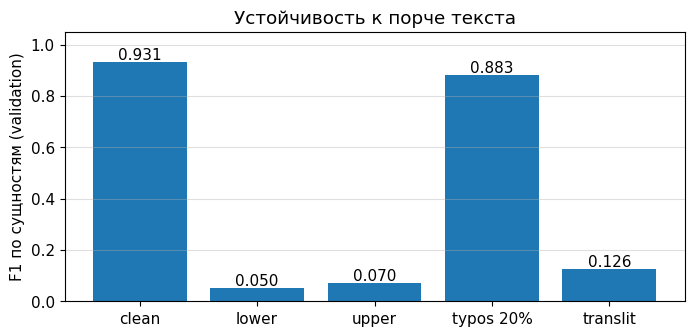

In [33]:
if '6.3' in BONUS_TASKS:
    shift_rng = random.Random(SEED)

    # 1. виды порчи; каждая функция получает слово и возвращает испорченное слово
    TRANSLIT = {'а': 'a', 'б': 'b', 'в': 'v', 'г': 'g', 'д': 'd', 'е': 'e', 'ё': 'e', 'ж': 'zh', 'з': 'z',
                'и': 'i', 'й': 'y', 'к': 'k', 'л': 'l', 'м': 'm', 'н': 'n', 'о': 'o', 'п': 'p', 'р': 'r',
                'с': 's', 'т': 't', 'у': 'u', 'ф': 'f', 'х': 'kh', 'ц': 'ts', 'ч': 'ch', 'ш': 'sh',
                'щ': 'shch', 'ъ': '', 'ы': 'y', 'ь': '', 'э': 'e', 'ю': 'yu', 'я': 'ya'}

    def translit(word):
        result = ''
        for ch in word:
            low = ch.lower()
            if low in TRANSLIT:
                lat = TRANSLIT[low]
                if ch != low:
                    lat = lat.capitalize()
                result += lat
            else:
                result += ch
        return result or word

    def typo(word, p=0.2):
        # с вероятностью p в слове из 4+ букв делаем одну опечатку: перестановку, пропуск или замену буквы
        if len(word) < 4 or not word.isalpha() or shift_rng.random() > p:
            return word
        chars = list(word)
        i = shift_rng.randrange(1, len(chars) - 1)    # первую букву не трогаем
        kind = shift_rng.choice(['swap', 'delete', 'replace'])
        if kind == 'swap':
            chars[i], chars[i + 1] = chars[i + 1], chars[i]
        elif kind == 'delete':
            del chars[i]
        else:
            chars[i] = shift_rng.choice('абвгдеёжзийклмнопрстуфхцчшщыэюя')
        return ''.join(chars)

    corruptions = {
        'clean': lambda w: w,
        'lower': lambda w: w.lower(),
        'upper': lambda w: w.upper(),
        'typos 20%': typo,
        'translit': translit,
    }

    # 2. для каждой порчи считаем метрики; метки и число слов не меняются
    shift_result = {}
    example_i = 0
    for name, fn in corruptions.items():
        corrupted = [[fn(w) for w in ws] for ws in val_tokens]
        assert all(len(a) == len(b) for a, b in zip(corrupted, val_tokens))
        pred = predict_word_tags(model, corrupted)
        scores = entity_scores(val_gold, pred)
        scores['token_f1'] = token_f1(val_gold, pred)
        report = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        scores['per_type_f1'] = {t: report[t]['f1-score'] for t in ENTITY_TYPES}
        n_sub = sum(len(tokenizer.tokenize(w)) for ws in corrupted[:300] for w in ws)
        n_w = sum(len(ws) for ws in corrupted[:300])
        scores['subwords_per_word'] = n_sub / n_w
        shift_result[name] = scores
        print(f'{name:<10}', ' '.join(corrupted[example_i][:14]))

    clean_f1 = shift_result['clean']['f1_micro']
    print(f'\n{"порча":<11}{"F1 micro":>9}{"Δ к clean":>11}{"token F1":>10}'
          + ''.join(f'{t:>7}' for t in ENTITY_TYPES) + f'{"сабв/слово":>12}')
    for name, s in shift_result.items():
        print(f'{name:<11}{s["f1_micro"]:>9.3f}{s["f1_micro"] - clean_f1:>+11.3f}{s["token_f1"]:>10.3f}'
              + ''.join(f'{s["per_type_f1"][t]:>7.3f}' for t in ENTITY_TYPES) + f'{s["subwords_per_word"]:>12.2f}')

    names = list(shift_result)
    plt.figure(figsize=(8, 3.5))
    plt.bar(names, [shift_result[n]['f1_micro'] for n in names])
    for i, n in enumerate(names):
        plt.text(i, shift_result[n]['f1_micro'] + 0.01, f'{shift_result[n]["f1_micro"]:.3f}', ha='center')
    plt.ylim(0, 1.05)
    plt.ylabel('F1 по сущностям (validation)')
    plt.title('Устойчивость к порче текста')
    plt.grid(True, axis='y', alpha=0.4)
    plt.show()

    (ARTIFACTS / 'bonus_6_3_shift.json').write_text(
        json.dumps(json_ready(shift_result), ensure_ascii=False, indent=2), encoding='utf-8')

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего F1 роняет перевод в нижний регистр, с 0.931 до 0.050. Почти так же плохо работают верхний регистр (0.070) и транслит (0.126), а опечатки в 20% длинных слов снижают F1 всего до 0.883.

Самое интересное, что нижний регистр почти не меняет разбиение на сабворды (1.24 сабворда на слово против 1.14 у чистого текста), а модель всё равно перестаёт находить сущности. Значит, главный признак, на который она опирается, это заглавная буква. В Collection3 практически все сущности написаны с большой буквы, и модель выучила этот простой сигнал вместо смысла. Слова «обама» или «грузии» она видит, но без заглавной буквы не считает их именами. С верхним регистром проблема двойная. Пропадает разница между именами собственными и обычными словами, а токенизатор режет слова капсом намного мельче (3.47 сабворда на слово), потому что такие формы редко встречались в словаре. Немного держатся только локации (0.195), видимо за счёт аббревиатур вроде «США», которые и так пишутся капсом. Транслит тоже дробит слова (2.46 сабворда на слово), и русская модель почти не видела латиницу при предобучении. Лучше всего здесь сохраняются персоны (0.290), потому что латинские слова с заглавной буквы похожи на иностранные имена, которые встречались в новостях.

Опечатки почти не мешают, потому что первая буква и регистр остаются на месте, а слово режется лишь чуть иначе (1.34 сабворда на слово). Модель узнаёт его по оставшимся кускам и контексту. Если модель должна работать на текстах из соцсетей или распознанной речи без регистра, её нужно дообучать с аугментацией регистра, например случайно переводить часть предложений train в нижний регистр.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [34]:
if '6.4' in BONUS_TASKS:
    import io
    import platform
    import warnings
    warnings.filterwarnings('ignore', category=DeprecationWarning)
    from torch.ao.quantization import quantize_dynamic

    cpu = torch.device('cpu')
    if 'x86' in torch.backends.quantized.supported_engines:
        torch.backends.quantized.engine = 'x86'
    print(f'CPU: {platform.processor() or platform.machine()}, потоков torch: {torch.get_num_threads()}')

    # один и тот же батч для замера задержки: 32 предложения validation
    bench_tokens = val_tokens[:32]
    # подмножество validation для проверки F1
    q_tokens, q_gold = val_tokens[:500], val_gold[:500]

    def size_mb(m):
        buf = io.BytesIO()
        torch.save(m.state_dict(), buf)
        return buf.getbuffer().nbytes / 2**20

    @torch.inference_mode()
    def latency_ms(m, tok, n_warmup=3, n_runs=20):
        enc = tok(bench_tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                  padding=True, return_tensors='pt')
        m.eval()
        for _ in range(n_warmup):          # прогрев
            m(**enc)
        times = []
        for _ in range(n_runs):
            start = time.perf_counter()
            m(**enc)
            times.append((time.perf_counter() - start) * 1000)
        return float(np.mean(times)), float(np.std(times))

    to_compare = [('rubert-tiny2', model, tokenizer)]
    if '6.2' in BONUS_TASKS:
        to_compare.append(('rubert-base-cased', other_model, other_tok))

    speed_result = {}
    for name, m, tok in to_compare:
        fp32_model = copy.deepcopy(m).to(cpu).eval()
        # квантуем только nn.Linear: веса в int8, активации квантуются на лету
        int8_model = quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8)

        linear_params = sum(mod.weight.numel() for mod in fp32_model.modules() if isinstance(mod, torch.nn.Linear))
        all_params = sum(p.numel() for p in fp32_model.parameters())

        row = {'linear_share': linear_params / all_params}
        for variant, mm in [('fp32', fp32_model), ('int8', int8_model)]:
            mean_ms, std_ms = latency_ms(mm, tok)
            pred = predict_word_tags(mm, q_tokens, tok=tok, dev=cpu)
            row[variant] = dict(latency_ms=mean_ms, latency_std=std_ms, size_mb=size_mb(mm),
                                f1=f1_score(q_gold, pred))
        row['speedup'] = row['fp32']['latency_ms'] / row['int8']['latency_ms']
        row['f1_change'] = row['int8']['f1'] - row['fp32']['f1']
        speed_result[name] = row

    print(f'\nбатч 32 предложения, CPU, среднее по 20 запускам после прогрева; F1 на первых 500 предложениях validation')
    print(f'{"модель":<19}{"доля Linear":>12}{"вариант":>9}{"задержка, мс":>15}{"размер, MB":>12}{"F1":>8}')
    for name, row in speed_result.items():
        for variant in ['fp32', 'int8']:
            r = row[variant]
            print(f'{name:<19}{row["linear_share"]:>12.1%}{variant:>9}'
                  f'{r["latency_ms"]:>9.1f} ± {r["latency_std"]:<4.1f}{r["size_mb"]:>12.1f}{r["f1"]:>8.4f}')
        print(f'{"":<19}ускорение x{row["speedup"]:.2f}, изменение F1 {row["f1_change"]:+.4f}\n')

    (ARTIFACTS / 'bonus_6_4_quantization.json').write_text(
        json.dumps(json_ready(speed_result), ensure_ascii=False, indent=2), encoding='utf-8')

CPU: x86_64, потоков torch: 1


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(



батч 32 предложения, CPU, среднее по 20 запускам после прогрева; F1 на первых 500 предложениях validation
модель              доля Linear  вариант   задержка, мс  размер, MB      F1
rubert-tiny2               7.9%     fp32     85.2 ± 5.2        111.0  0.9275
rubert-tiny2               7.9%     int8     80.8 ± 3.9        104.5  0.9243
                   ускорение x1.05, изменение F1 -0.0031

rubert-base-cased         47.9%     fp32   2407.6 ± 316.9       676.3  0.9768
rubert-base-cased         47.9%     int8   1958.2 ± 232.4       433.3  0.9722
                   ускорение x1.23, изменение F1 -0.0046



**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Я применила динамическую квантизацию, в которой веса всех `nn.Linear` хранятся в int8, и замеряла задержку на CPU (x86_64, 1 поток torch) на одном батче из 32 предложений validation, со средним по 20 запускам после прогрева. Для rubert-tiny2 ускорение почти нулевое, 85.2 мс против 80.8 мс (в 1.05 раза), а F1 на первых 500 предложениях validation снизился на 0.0031 (с 0.9275 до 0.9243). Для rubert-base-cased выигрыш больше, 2408 мс против 1958 мс (в 1.23 раза), F1 снизился на 0.0046 (с 0.9768 до 0.9722), а размер модели уменьшился с 676 до 433 MB. Падение метрики в обоих случаях меньше половины пункта, то есть квантизация почти не вредит качеству. В прошлом запуске у tiny2 у меня получалось ускорение 1.38, но тогда разброс fp32 был ±28 мс, так что тот результат был шумом, а новый замер стабильнее.

Выигрыш зависит от модели, потому что квантизация трогает только линейные слои. У rubert-tiny2 92% параметров лежат в таблице эмбеддингов, а на Linear приходится всего 7.9%, поэтому размер почти не изменился (111 MB против 104.5 MB). Матрицы в её слоях маленькие (312 × 312 и 312 × 600), умножение на них и так быстрое, и выигрыш от int8 съедают накладные расходы на квантование активаций перед каждым слоем, а также attention, softmax и LayerNorm, которые остались в float32. У rubert-base-cased на Linear приходится почти половина параметров (47.9%), а матрицы большие (768 × 768 и 768 × 3072). Основное время уходит именно на их умножение, поэтому int8 даёт заметное ускорение и сжатие. Квантизация выгодна для моделей, где основная часть вычислений и параметров сидит в больших линейных слоях, а для маленькой модели с огромным словарём она почти ничего не даёт.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

порог 0: F1 0.9305, seqeval F1 0.9305

уверенность   лучший порог  precision   recall      F1  прирост F1
mean                  0.81      0.944    0.928  0.9360     +0.0055
min                   0.71      0.943    0.928  0.9355     +0.0050
порог 0:    precision 0.918, recall 0.943, F1 0.9305


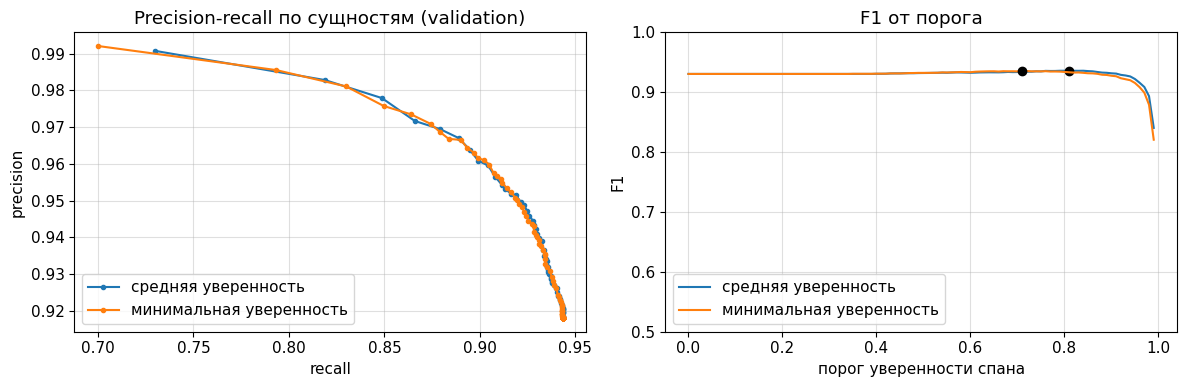

In [35]:
if '6.5' in BONUS_TASKS:
    # 1. предсказания validation вместе с уверенностью каждого слова
    thr_tags, thr_conf = predict_word_tags(model, val_tokens, return_probs=True)

    # 2. истинные спаны и предсказанные спаны с уверенностью (средней и минимальной по словам спана)
    gold_sets = [set(bio_to_spans(g)) for g in val_gold]
    pred_items = []
    for tags, conf in zip(thr_tags, thr_conf):
        items = []
        for span in bio_to_spans(tags):
            span_conf = conf[span[0]:span[1]]
            items.append((span, float(np.mean(span_conf)), float(min(span_conf))))
        pred_items.append(items)
    n_gold_spans = sum(len(g) for g in gold_sets)

    def prf_at_threshold(thr, kind):
        pos = 1 if kind == 'mean' else 2
        tp, n_pred = 0, 0
        for gold_spans, items in zip(gold_sets, pred_items):
            for item in items:
                if item[pos] >= thr:
                    n_pred += 1
                    if item[0] in gold_spans:
                        tp += 1
        precision = tp / n_pred if n_pred else 0.0
        recall = tp / n_gold_spans if n_gold_spans else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return precision, recall, f1

    # проверка: при пороге 0 должен получиться тот же F1, что и у seqeval
    p0, r0, f0 = prf_at_threshold(0.0, 'mean')
    seq_f1 = entity_scores(val_gold, thr_tags)['f1_micro']
    print(f'порог 0: F1 {f0:.4f}, seqeval F1 {seq_f1:.4f}')
    assert abs(f0 - seq_f1) < 1e-9

    # 3. перебор порогов
    thresholds = np.round(np.arange(0.0, 1.0, 0.01), 2)
    curves = {}
    threshold_result = {}
    for kind in ['mean', 'min']:
        rows = [prf_at_threshold(t, kind) for t in thresholds]
        curves[kind] = rows
        best_i = int(np.argmax([r[2] for r in rows]))
        threshold_result[kind] = dict(best_threshold=float(thresholds[best_i]),
                                      precision=rows[best_i][0], recall=rows[best_i][1], f1=rows[best_i][2],
                                      f1_at_zero=f0, gain=rows[best_i][2] - f0)

    print(f'\n{"уверенность":<12}{"лучший порог":>14}{"precision":>11}{"recall":>9}{"F1":>8}{"прирост F1":>12}')
    for kind, r in threshold_result.items():
        print(f'{kind:<12}{r["best_threshold"]:>14.2f}{r["precision"]:>11.3f}{r["recall"]:>9.3f}'
              f'{r["f1"]:>8.4f}{r["gain"]:>+12.4f}')
    print(f'порог 0:    precision {p0:.3f}, recall {r0:.3f}, F1 {f0:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for kind, label in [('mean', 'средняя'), ('min', 'минимальная')]:
        prec = [r[0] for r in curves[kind]]
        rec = [r[1] for r in curves[kind]]
        f1s = [r[2] for r in curves[kind]]
        axes[0].plot(rec, prec, '.-', label=f'{label} уверенность')
        axes[1].plot(thresholds, f1s, '-', label=f'{label} уверенность')
        best = threshold_result[kind]
        axes[1].plot(best['best_threshold'], best['f1'], 'o', color='black')
    axes[0].set(title='Precision-recall по сущностям (validation)', xlabel='recall', ylabel='precision')
    axes[1].set(title='F1 от порога', xlabel='порог уверенности спана', ylabel='F1')
    axes[1].set_ylim(0.5, 1.0)
    for ax in axes:
        ax.grid(True, alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

    (ARTIFACTS / 'bonus_6_5_threshold.json').write_text(
        json.dumps(json_ready(threshold_result), ensure_ascii=False, indent=2), encoding='utf-8')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший F1 даёт порог 0.81 по средней уверенности. F1 растёт с 0.9305 до 0.9360, то есть на 0.0055. По минимальной уверенности лучший порог 0.71, он даёт почти то же самое, 0.9355 (прирост 0.0050). Прирост около половины пункта F1. На графике F1 почти не меняется на всём отрезке от 0 до 0.8 и резко падает только после 0.95. Модель и так очень уверена в большинстве своих спанов, поэтому отсекать почти нечего. При этом порог подобран на validation, а разброс F1 между моими прогонами около 0.003, так что такой маленький выигрыш вполне может не повториться на test.

Средняя уверенность усредняет вероятности по всем словам спана, поэтому одно сомнительное слово в длинном названии почти не влияет на оценку. Минимальная уверенность строже, спан считается настолько надёжным, насколько надёжно его самое слабое слово. Поэтому при одинаковом пороге минимальная уверенность выкидывает больше спанов, и её оптимальный порог ниже (0.71 против 0.81). В моём прогоне оба способа дали почти одинаковый результат.

Порог не может поднять recall, потому что он только убирает предсказанные спаны и никогда не добавляет новые. Recall равен доле истинных сущностей, которые модель нашла. Сущность, которую модель пропустила, не появится от изменения порога, а если отбросить верный, но неуверенный спан, recall только упадёт. Поэтому recall снижается с 0.943 до 0.928, а F1 растёт только за счёт precision, которая поднимается с 0.918 до 0.944.